## Código do _conveyor_plot.ipynb_

Plota o cad da esteira e extrai segmentos dela

In [1]:
import math
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from ezdxf import recover
from ezdxf.addons.drawing import Frontend, RenderContext
from ezdxf.addons.drawing.matplotlib import MatplotlibBackend
from ezdxf.math import Matrix44, Vec3
from matplotlib.lines import Line2D
from matplotlib.patches import Arc, Circle, Rectangle
from plotly.subplots import make_subplots

In [2]:
try:
    doc, auditor = recover.readfile("esteira_ufmg_verlab-Sketch.dxf")
except IOError:
    print(f"Not a DXF file or a generic I/O error.")
except ezdxf.DXFStructureError:
    print(f"Invalid or corrupted DXF file.")

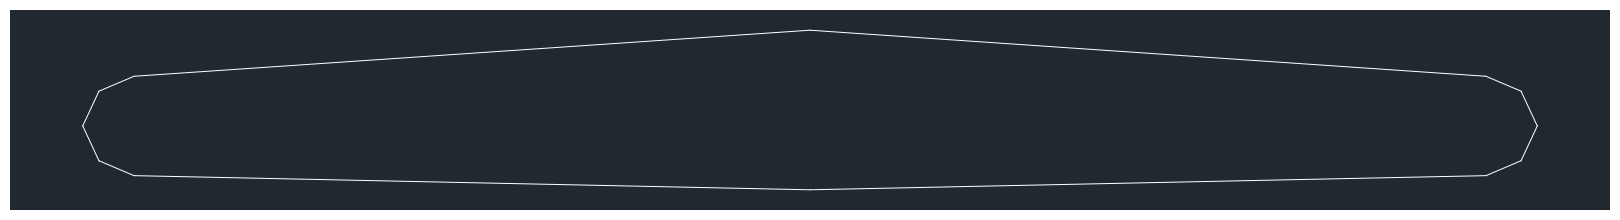

In [3]:
# The auditor.errors attribute stores severe errors, which may raise exceptions when rendering.
if not auditor.has_errors:
    fig = plt.figure()
    ax = fig.add_axes([0, 0, 1, 1])
    ctx = RenderContext(doc)
    out = MatplotlibBackend(ax)
    Frontend(ctx, out).draw_layout(doc.modelspace(), finalize=True)
    fig.savefig("your.png", dpi=300)

In [4]:
def circle_array(xc, yc, r, start, end):
    phi1 = start * np.pi / 180.0
    phi2 = end * np.pi / 180.0
    dphi = (phi2 - phi1) / np.ceil(200 * np.pi * r * (phi2 - phi1))  # 根据圆弧周长设置等间距
    array = np.arange(phi1, phi2, dphi)
    return xc + r * np.cos(array), yc + r * np.sin(array)


lines = []
circles = []
arcs = []
ellipses = []
splines = []
polylines = []

msp = doc.modelspace()
for entity in msp:
    transform = Matrix44()
    if entity.dxftype() == "LINE":
        start = transform.transform(entity.dxf.start)
        end = transform.transform(entity.dxf.end)
        lines.append((start, end))
    elif entity.dxftype() == "LWPOLYLINE":
        polyline = [transform.transform((p[0], p[1], 0)) for p in entity.get_points()]
        polylines.append(polyline)
    elif entity.dxftype() == "CIRCLE":
        center = transform.transform(entity.dxf.center)
        radius = entity.dxf.radius
        circles.append((center, radius))
    elif entity.dxftype() == "ARC":
        center = transform.transform(entity.dxf.center)
        radius = entity.dxf.radius
        start_angle = entity.dxf.start_angle
        end_angle = entity.dxf.end_angle
        arcs.append((center, radius, start_angle, end_angle))
    elif entity.dxftype() == "ELLIPSE":
        center = transform.transform(entity.dxf.center)
        major_axis_vec = Vec3(entity.dxf.major_axis)
        transformed_major_axis = transform.transform_direction(major_axis_vec)

        major_len = transformed_major_axis.magnitude
        angle_rad = math.atan2(transformed_major_axis.y, transformed_major_axis.x)
        rotation_deg = math.degrees(angle_rad)

        ratio = entity.dxf.ratio
        ellipses.append((center, major_len, ratio, rotation_deg))
    elif entity.dxftype() == "SPLINE":
        control_points = [transform.transform(p) for p in entity.control_points]
        fit_points = [transform.transform(p) for p in entity.fit_points]
        splines.append((control_points, fit_points))

print(f"lines:{len(lines)}")
print(f"circles:{len(circles)}")
print(f"arcs:{len(arcs)}")
print(f"ellipses:{len(ellipses)}")
print(f"splines:{len(splines)}")
print(f"polylines:{len(polylines)}")

lines:12
circles:0
arcs:0
ellipses:0
splines:0
polylines:0


## Código que plota os dados associados ao Cad da esteira

Ainda sem nenhuma forma de alinhamento dos dados. Dados são plotados a partir do ponto inicial do CAD da esteira, que por acaso coincide com um local próximo de onde o ímã estava no momento da coleta desses dados.

Esses dados são os coletados pelo primeiro sensor.

In [5]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

all_raw_segments = []

# extrai segmentos de linhas sem a coordenada Z
for line in lines:
    p1 = (line[0][0], line[0][1])  # pt do inicio da linha
    p2 = (line[1][0], line[1][1])  # pt final da linha
    all_raw_segments.append((p1, p2))


# ordena uma lista de segmentos de linha pra formar um caminho continuo

def sort_segments(segments, tolerance=1e-5):
    if not segments:
        return []
    sorted_path = [segments.pop(0)]
    while segments:
        current_end_point = sorted_path[-1][1]
        found_next = False
        for i, segment in enumerate(segments):
            p_start, p_end = segment
            if np.linalg.norm(np.array(current_end_point) - np.array(p_start)) < tolerance:
                sorted_path.append(segments.pop(i))
                found_next = True
                break
            elif np.linalg.norm(np.array(current_end_point) - np.array(p_end)) < tolerance:
                # tinha linhas "invertidas" no cad, então inverte a ordem dos pontos
                sorted_path.append((p_end, p_start))
                segments.pop(i)
                found_next = True
                break
        if not found_next:
            print("Nem todos os segmentos foram conectados")
            break
    return sorted_path

sorted_segments = sort_segments(all_raw_segments)
pontos_do_contorno = [segment[0] for segment in sorted_segments]
pontos_do_contorno.append(sorted_segments[-1][1])
conveyor_path = np.array(pontos_do_contorno)
conveyor_path[:, 0] = conveyor_path[:, 0] * -1


In [6]:


# Plotagem do CAD da esteira e dos dados do log associados

df = pd.read_csv('log_esteira_2025-07-11_15-56-06_1236027310.csv')
n_samples = len(df)

def interpolate_path(path, num_points):
    segment_lengths = np.sqrt(np.sum(np.diff(path, axis=0)**2, axis=1))
    total_length = np.sum(segment_lengths)
    cumulative_lengths = np.zeros(len(path))
    cumulative_lengths[1:] = np.cumsum(segment_lengths)
    distances = np.linspace(0, total_length, num_points)
    interpolated_points = np.zeros((num_points, 2))
    for i, d in enumerate(distances):
        segment_index = np.searchsorted(cumulative_lengths, d, side='right') - 1
        if segment_index < 0: segment_index = 0
        if segment_index >= len(segment_lengths):
            interpolated_points[i] = path[-1]
            continue
        distance_into_segment = d - cumulative_lengths[segment_index]
        segment_vector = path[segment_index + 1] - path[segment_index]
        if segment_lengths[segment_index] > 0:
            interpolation_ratio = distance_into_segment / segment_lengths[segment_index]
            interpolated_points[i] = path[segment_index] + interpolation_ratio * segment_vector
        else:
            interpolated_points[i] = path[segment_index]
    return interpolated_points

interpolated_points = interpolate_path(conveyor_path, n_samples)

hover_texts = []
for index, row in df.iterrows():
    text = (f"<b>Timestamp:</b> {row['timestamp_us']}<br>" +
            f"<b>rotX:</b> {row['rotX']:.2f}<br><b>rotY:</b> {row['rotY']:.2f}<br><b>rotZ:</b> {row['rotZ']:.2f}<br>" +
            f"<b>gForceX:</b> {row['gForceX']:.4f}<br><b>gForceY:</b> {row['gForceY']:.4f}<br><b>gForceZ:</b> {row['gForceZ']:.4f}")
    hover_texts.append(text)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=conveyor_path[:, 0], y=conveyor_path[:, 1], mode='lines',
    line=dict(color='black', width=2), name='Contorno da Esteira'
))
fig.add_trace(go.Scatter(
    x=interpolated_points[:, 0], y=interpolated_points[:, 1], mode='markers',
    marker=dict(size=6, color=df['gForceX'], colorscale='Viridis', showscale=True, colorbar=dict(title='gForceX')),
    hoverinfo='text', hovertext=hover_texts, name='Dados do Log'
))
fig.update_layout(
    yaxis_scaleanchor="x", yaxis_scaleratio=1,
    showlegend=True, width=900, height=700
)

fig.show()

c:\Users\Raiza\anaconda3\Lib\site-packages\kaleido\_sync_server.py:11: UserWarning:




This means that static image generation (e.g. `fig.write_image()`) will not work.

Please upgrade Plotly to version 6.1.1 or greater, or downgrade Kaleido to version 0.2.1.




## Plotando os dados coletados com o sensor da vale

1871


<Axes: title={'center': 'Giroscópio vs Amostras'}, xlabel='Amostras', ylabel='gyro'>

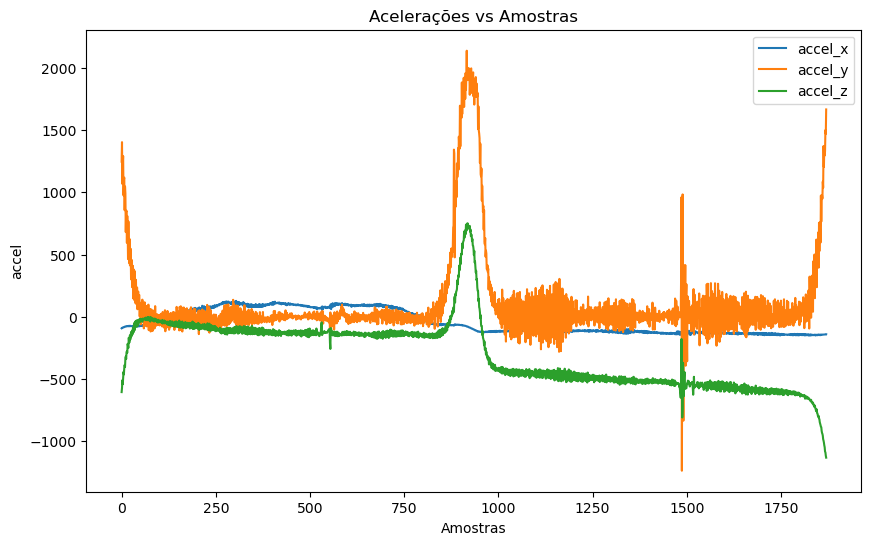

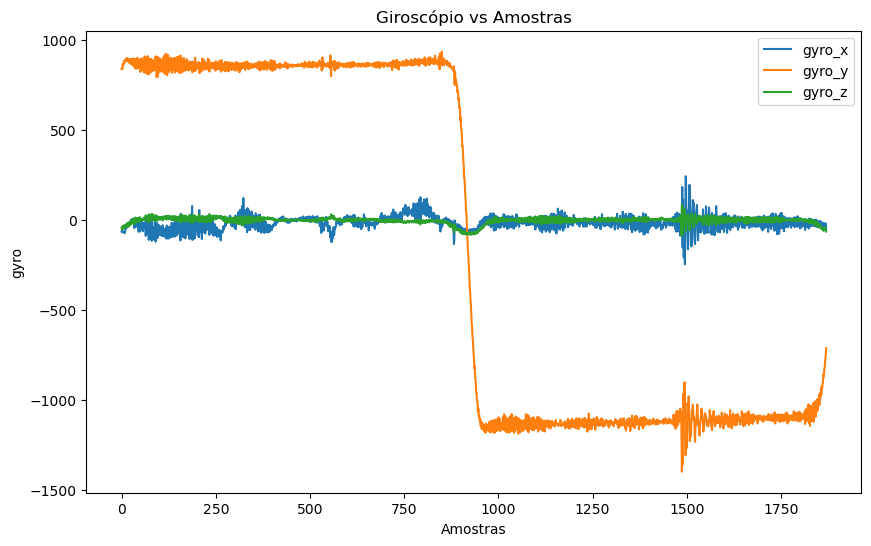

In [7]:
# plot de 1 coleta df_ref
df_ref = pd.read_csv('logs_sensor_vale\logs_vel_1\log_tcp_2025-10-21_20-12-45_192.168.1.131.csv')
n_samples_ref = len(df_ref)
print (n_samples_ref)

df_ref.plot(y=['accel_x', 'accel_y', 'accel_z'], title='Acelerações vs Amostras', xlabel='Amostras', ylabel='accel', figsize=(10, 6))

df_ref.plot(y=['gyro_x', 'gyro_y', 'gyro_z'], title='Giroscópio vs Amostras', xlabel='Amostras', ylabel='gyro', figsize=(10, 6))

Os dados plotados a seguir foram coletados com a intenção de servirem como base para o DTW. 

Deixei o sensor parado na ponta da esteira, logo abaixo do ímã, de modo que ele ficasse enviando coletas sem parar. Assim que uma coleta fosse recebida, eu ligava o motor da esteira (na velocidade 1, 2, 3 ou 4) e coletava os dados de uma volta completa. 

Porém, ao plotar, ficou visível que essa estratégia não fucnionou.

103 1812 555 104


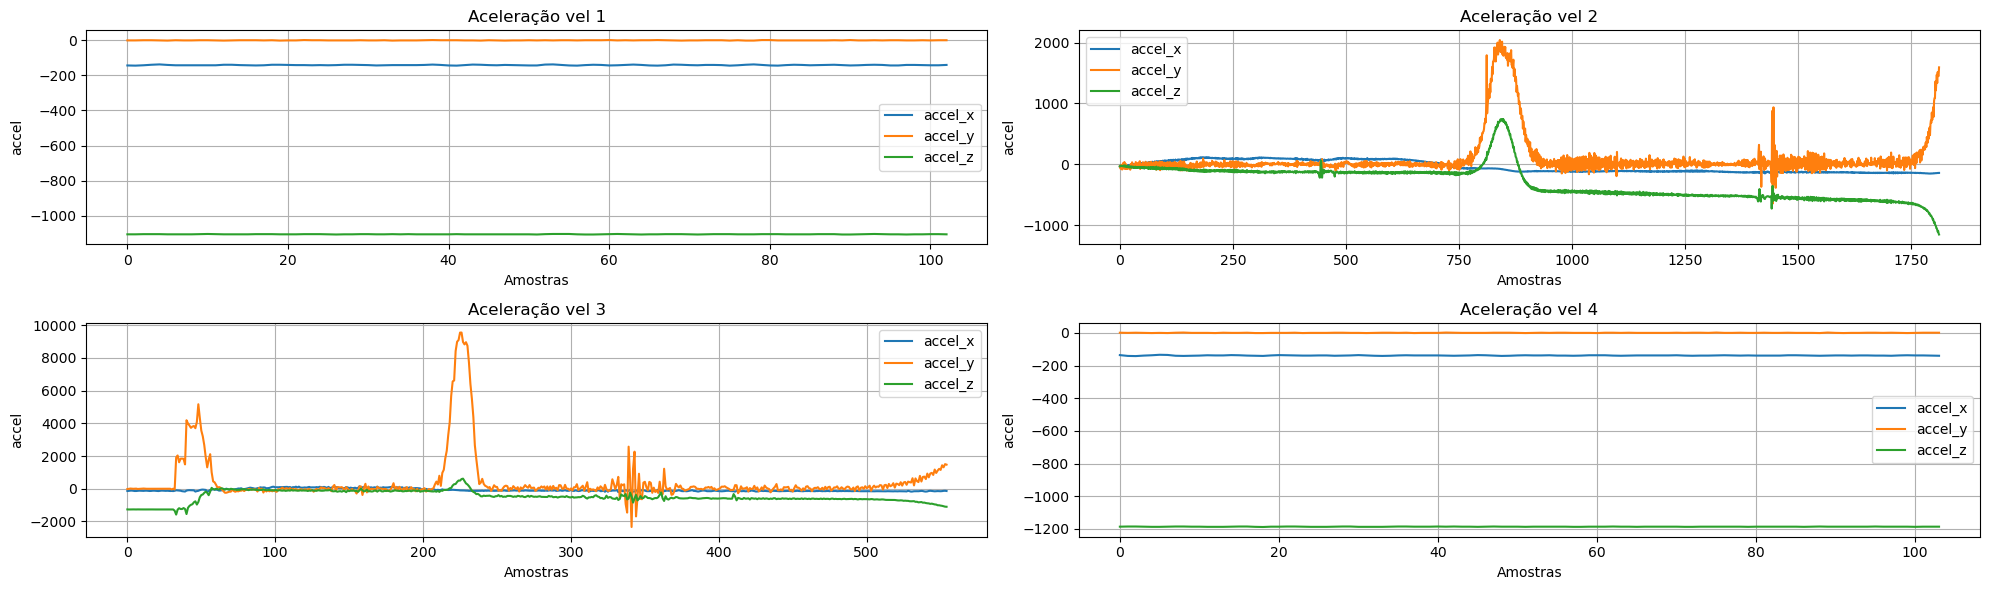

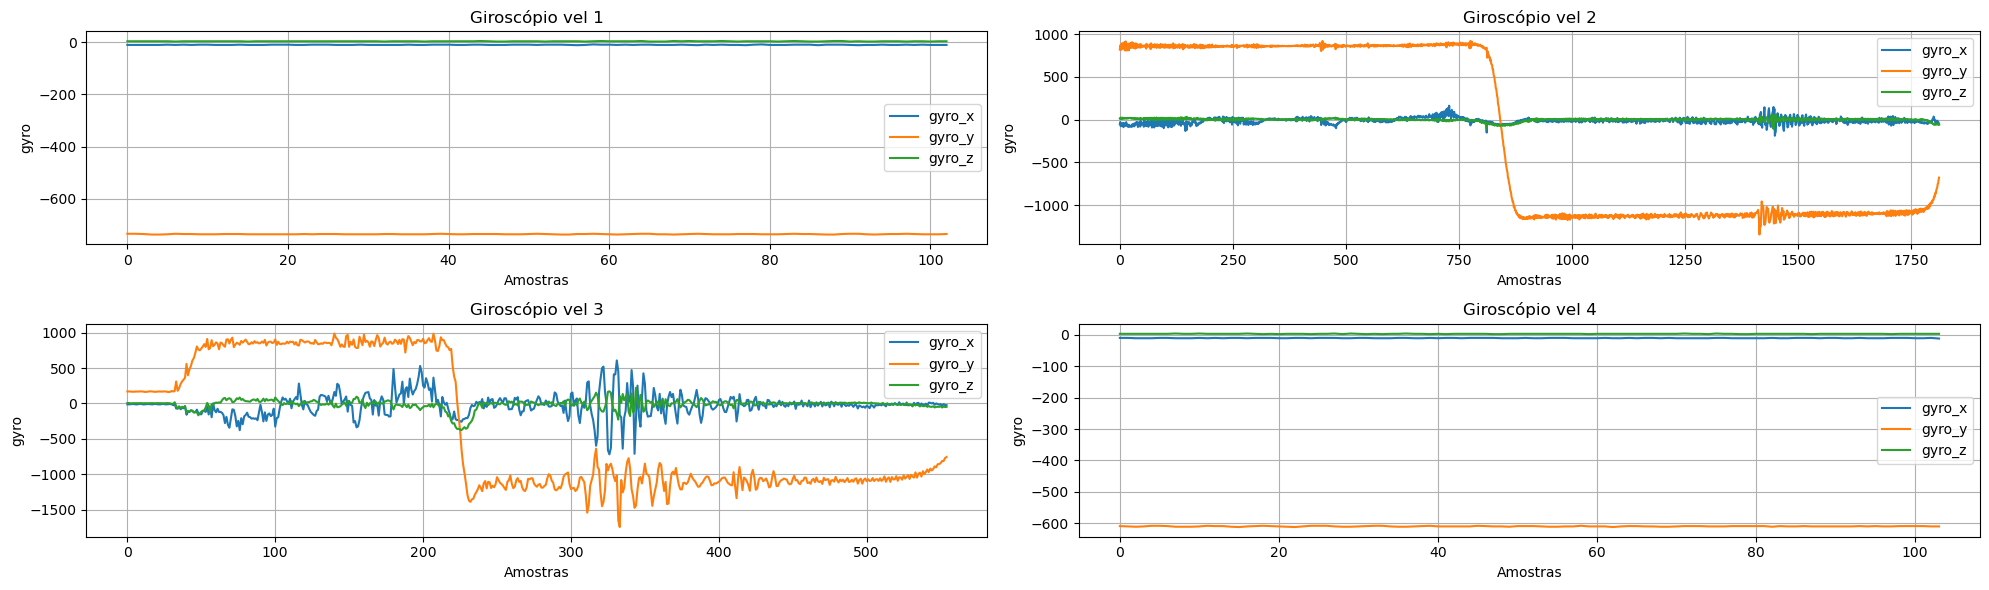

In [8]:
df_pfto_1 = pd.read_csv('logs_sensor_vale\log_pfto_vel_1\log_tcp_2025-10-21_20-00-58_192.168.1.131.csv')
df_pfto_2 = pd.read_csv('logs_sensor_vale\log_pfto_vel_2\log_tcp_2025-10-21_20-01-46_192.168.1.131.csv')
df_pfto_3 = pd.read_csv('logs_sensor_vale\log_pfto_vel_3\log_tcp_2025-10-21_20-05-40_192.168.1.131.csv')
df_pfto_4 = pd.read_csv('logs_sensor_vale\log_pfto_vel_4\log_tcp_2025-10-21_20-08-21_192.168.1.131.csv')

print(len(df_pfto_1), len(df_pfto_2), len(df_pfto_3), len(df_pfto_4))
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(20, 6))

# acelerometro:
df_pfto_1.plot(y=['accel_x', 'accel_y', 'accel_z'], # velocidade 1
            title='Aceleração vel 1',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[0, 0],
            grid=True)
df_pfto_2.plot(y=['accel_x', 'accel_y', 'accel_z'], # velocidade 2
            title='Aceleração vel 2',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[0, 1],
            grid=True)
df_pfto_3.plot(y=['accel_x', 'accel_y', 'accel_z'], # vel 3
            title='Aceleração vel 3',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[1, 0],
            grid=True)

df_pfto_4.plot(y=['accel_x', 'accel_y', 'accel_z'], # vel 4
            title='Aceleração vel 4',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[1, 1],
            grid=True)
plt.tight_layout()
plt.show()

# giroscopio:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(20, 6))
df_pfto_1.plot(y=['gyro_x', 'gyro_y', 'gyro_z'], # vel 1
            title='Giroscópio vel 1',
            xlabel='Amostras',
            ylabel='gyro',
            ax=axes[0,0], 
            grid=True)
df_pfto_2.plot(y=['gyro_x', 'gyro_y', 'gyro_z'], # vel 2
            title='Giroscópio vel 2',
            xlabel='Amostras',
            ylabel='gyro',
            ax=axes[0,1], 
            grid=True)
df_pfto_3.plot(y=['gyro_x', 'gyro_y', 'gyro_z'], # vel 3
            title='Giroscópio vel 3',
            xlabel='Amostras',
            ylabel='gyro',
            ax=axes[1,0], 
            grid=True)
df_pfto_4.plot(y=['gyro_x', 'gyro_y', 'gyro_z'], # vel 4
            title='Giroscópio vel 4',
            xlabel='Amostras',
            ylabel='gyro',
            ax=axes[1,1], 
            grid=True)

plt.tight_layout()
plt.show()

Os dados plotados a seguir foram coletados da seguinte forma:

A cada momento que o sensor passava pelo ímã (depois de uma volta completa) em uma velocidade x, eu aumentava a velocidade da esteira para x+1, até passar por todas as 4 velocidades.

Porém esses dados também ficaram ruins.

3269 103 2460 1739


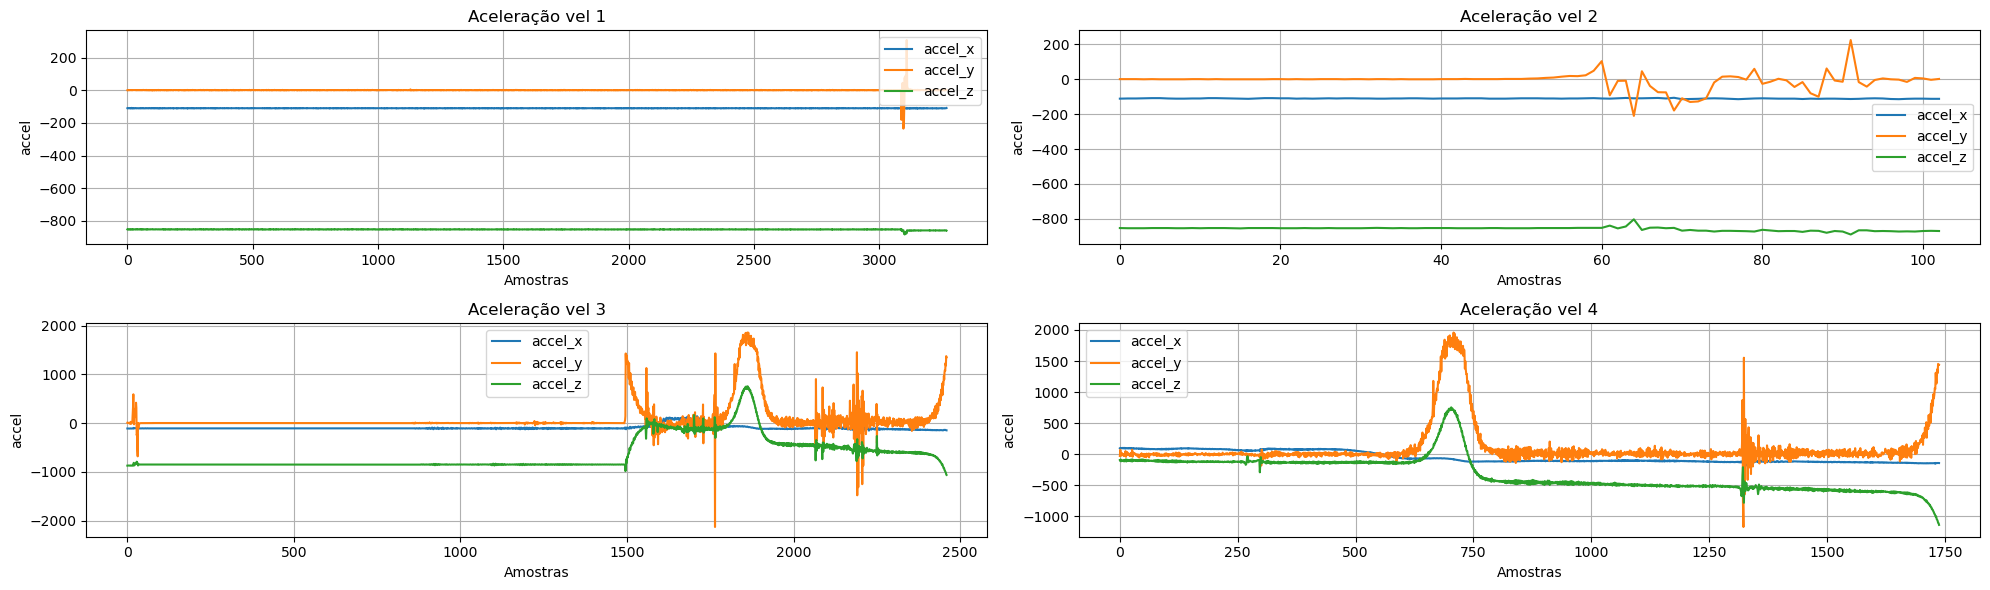

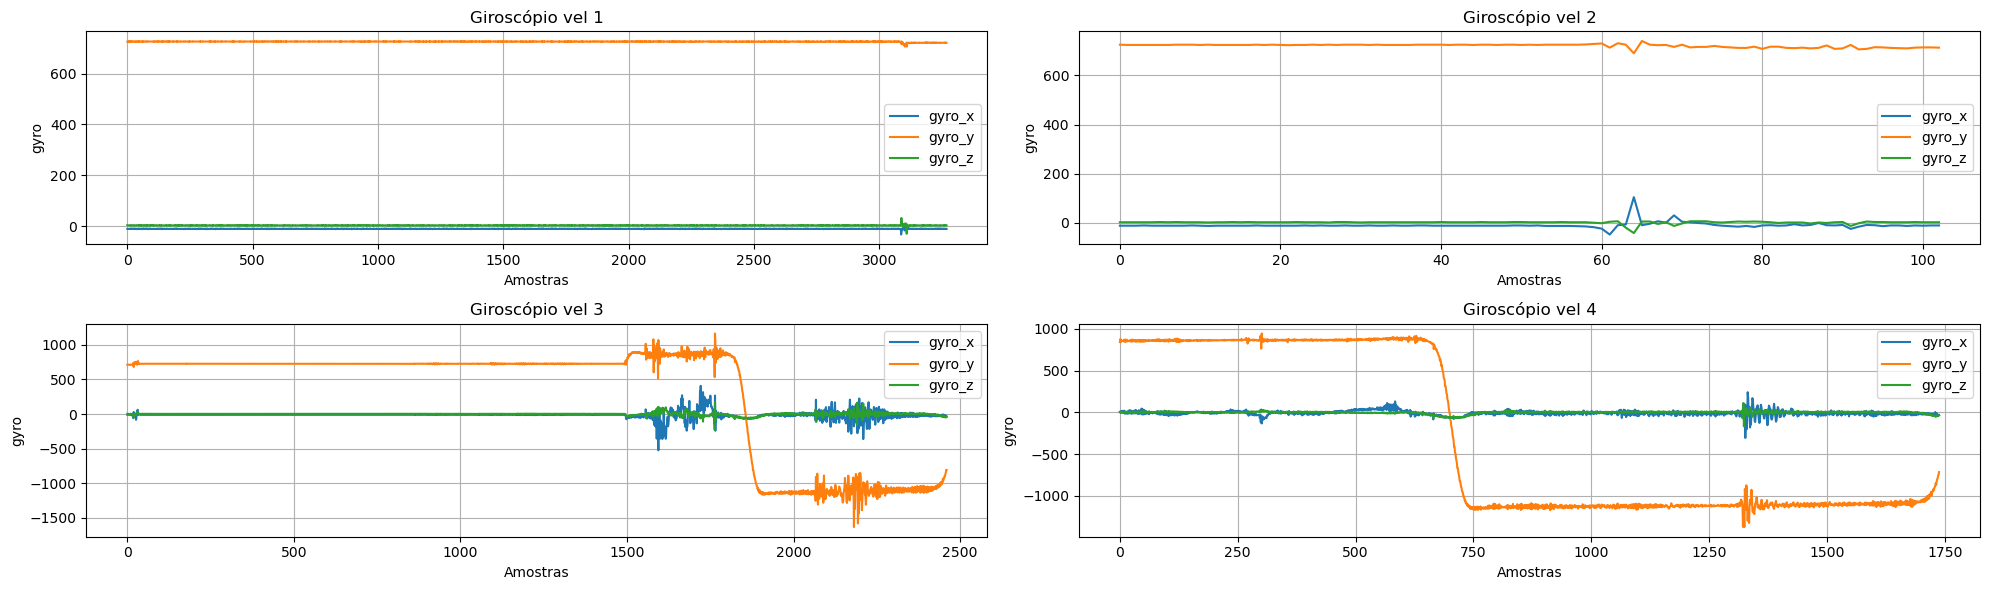

In [9]:
df_vel_var_1 = pd.read_csv('logs_sensor_vale\logs_esteira_vels_crescentes\log_tcp_2025-10-21_19-48-41_192.168.1.131.csv')
df_vel_var_2 = pd.read_csv('logs_sensor_vale\logs_esteira_vels_crescentes\log_tcp_2025-10-21_19-49-31_192.168.1.131.csv')
df_vel_var_3 = pd.read_csv('logs_sensor_vale\logs_esteira_vels_crescentes\log_tcp_2025-10-21_19-50-14_192.168.1.131.csv')
df_vel_var_4 = pd.read_csv('logs_sensor_vale\logs_esteira_vels_crescentes\log_tcp_2025-10-21_19-50-28_192.168.1.131.csv')

print(len(df_vel_var_1), len(df_vel_var_2), len(df_vel_var_3), len(df_vel_var_4))
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(20, 6))
df_vel_var_1.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Aceleração vel 1',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[0, 0], 
            grid=True)
df_vel_var_2.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Aceleração vel 2',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[0, 1],
            grid=True)
df_vel_var_3.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Aceleração vel 3',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[1, 0], 
            grid=True)
df_vel_var_4.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Aceleração vel 4',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[1, 1],
            grid=True)
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(20, 6))
df_vel_var_1.plot(y=['gyro_x', 'gyro_y', 'gyro_z'],
            title='Giroscópio vel 1',
            xlabel='Amostras',
            ylabel='gyro',
            ax=axes[0,0], 
            grid=True)
df_vel_var_2.plot(y=['gyro_x', 'gyro_y', 'gyro_z'],
            title='Giroscópio vel 2',
            xlabel='Amostras',
            ylabel='gyro',
            ax=axes[0,1],
            grid=True)
df_vel_var_3.plot(y=['gyro_x', 'gyro_y', 'gyro_z'],
            title='Giroscópio vel 3',
            xlabel='Amostras',
            ylabel='gyro',
            ax=axes[1,0], 
            grid=True)
df_vel_var_4.plot(y=['gyro_x', 'gyro_y', 'gyro_z'],
            title='Giroscópio vel 4',
            xlabel='Amostras',
            ylabel='gyro',
            ax=axes[1,1],
            grid=True)

plt.tight_layout()
plt.show()

Plotando 6 coletas escolhidas aleatoriamente para comparar as coletas entre si

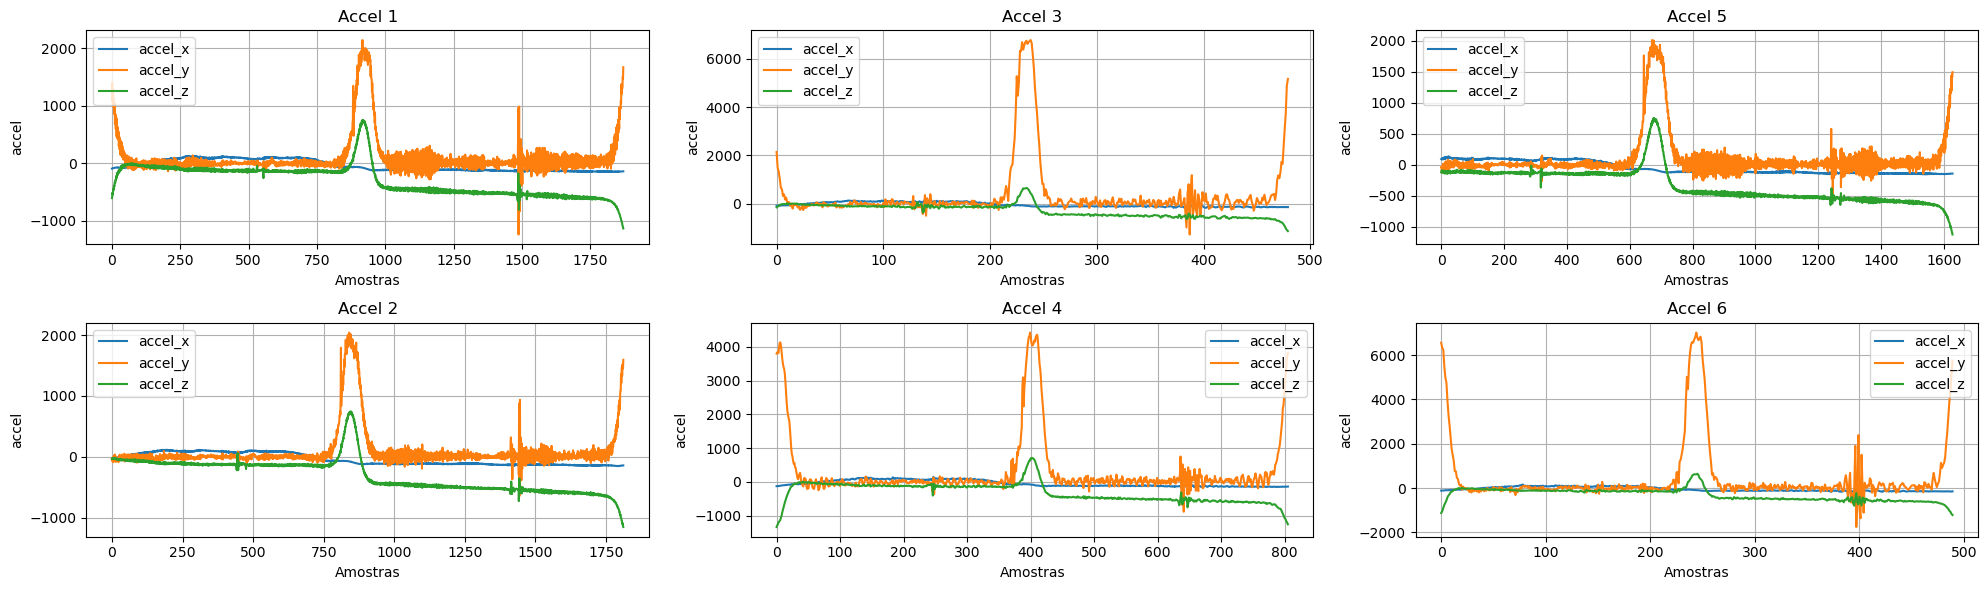

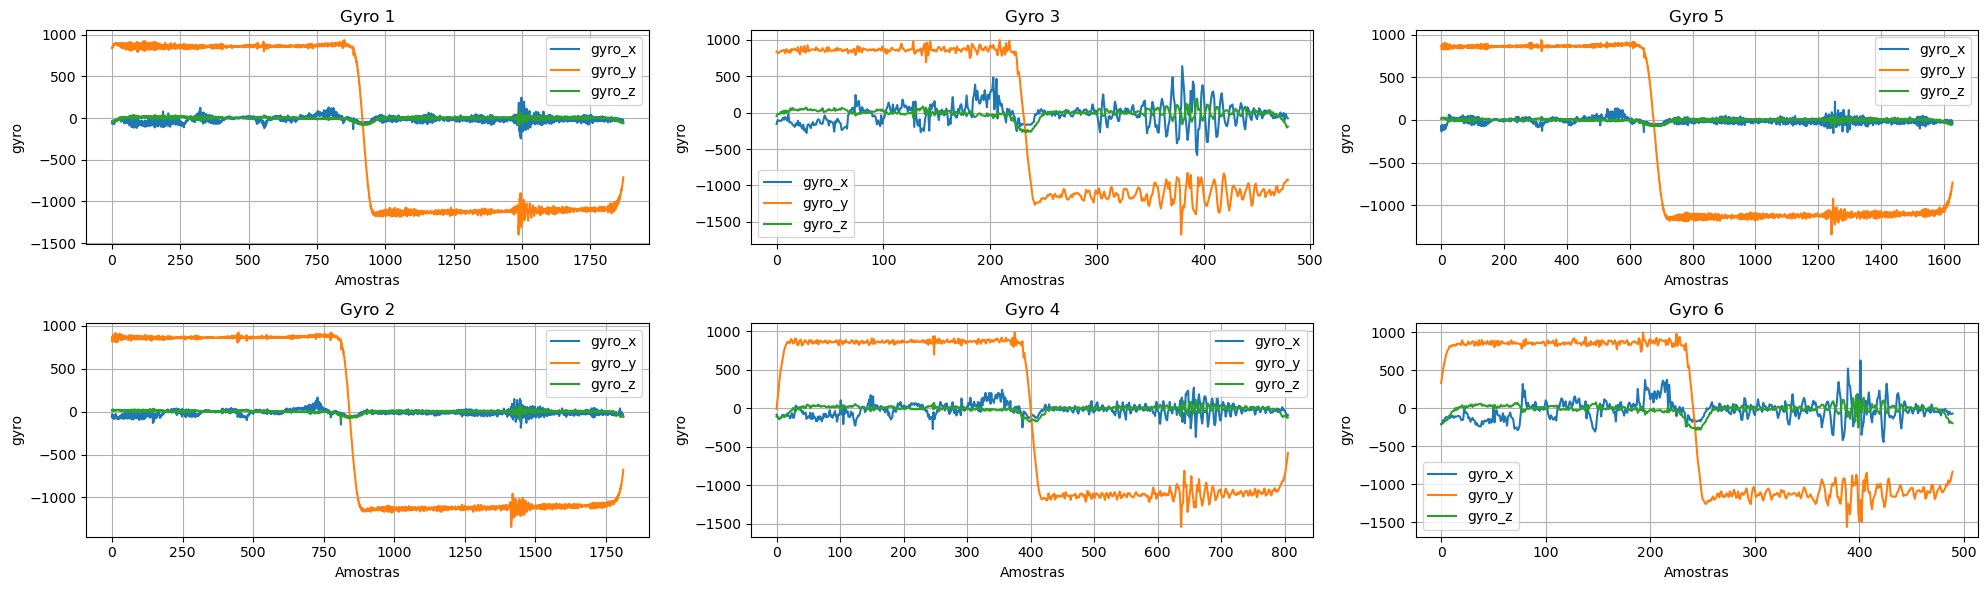

In [10]:
# plotando 6 coletas aleatorias pra comparar os dados

df_1 = pd.read_csv('logs_sensor_vale\logs_vel_1\log_tcp_2025-10-21_20-12-45_192.168.1.131.csv')
df_2 = pd.read_csv('logs_sensor_vale\log_pfto_vel_2\log_tcp_2025-10-21_20-01-46_192.168.1.131.csv')
df_3 = pd.read_csv('logs_sensor_vale\logs_vel_3\log_tcp_2025-10-21_20-06-49_192.168.1.131.csv')
df_4 = pd.read_csv('logs_sensor_vale\logs_vel_2\log_tcp_2025-10-21_20-04-07_192.168.1.131.csv')
df_5 = pd.read_csv('logs_sensor_vale\logs_vel_1\log_tcp_2025-10-21_20-14-42_192.168.1.131.csv')
df_6 = pd.read_csv('logs_sensor_vale\logs_vel_4\log_tcp_2025-10-21_20-07-59_192.168.1.131.csv')

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(20, 6))

df_1.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Accel 1',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[0, 0], 
            grid=True)
df_2.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Accel 2',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[1, 0],
            grid=True)
df_3.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Accel 3',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[0, 1], 
            grid=True)
df_4.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Accel 4',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[1, 1],
            grid=True)
df_5.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Accel 5',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[0, 2],
            grid=True)
df_6.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Accel 6',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[1, 2],
            grid=True)

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(20, 6))
df_1.plot(y=['gyro_x', 'gyro_y', 'gyro_z'],
            title='Gyro 1',
            xlabel='Amostras',
            ylabel='gyro',
            ax=axes[0,0], 
            grid=True)
df_2.plot(y=['gyro_x', 'gyro_y', 'gyro_z'],
            title='Gyro 2',
            xlabel='Amostras',
            ylabel='gyro',
            ax=axes[1,0],
            grid=True)
df_3.plot(y=['gyro_x', 'gyro_y', 'gyro_z'],
            title='Gyro 3',
            xlabel='Amostras',
            ylabel='gyro',
            ax=axes[0,1], 
            grid=True)
df_4.plot(y=['gyro_x', 'gyro_y', 'gyro_z'],
            title='Gyro 4',
            xlabel='Amostras',
            ylabel='gyro',
            ax=axes[1, 1],
            grid=True)
df_5.plot(y=['gyro_x', 'gyro_y', 'gyro_z'],
            title='Gyro 5',
            xlabel='Amostras',
            ylabel='gyro',
            ax=axes[0, 2],
            grid=True)
df_6.plot(y=['gyro_x', 'gyro_y', 'gyro_z'],
            title='Gyro 6',
            xlabel='Amostras',
            ylabel='gyro',
            ax=axes[1, 2],
            grid=True)

plt.tight_layout()
plt.show()

## Aplicação do DTW

In [11]:
# interpola o caminho da esteira para o numero de amostras do log df_ref
spatial_map = interpolate_path(conveyor_path, n_samples_ref)

In [12]:
ref_signal = df_ref['gyro_y'].values 
ref_signal_norm = (ref_signal - np.mean(ref_signal)) / np.std(ref_signal) # Giro y normalizado do df_ref

# log escolhido aleatoriamente
df_new = pd.read_csv('logs_sensor_vale\log_pfto_vel_2\log_tcp_2025-10-21_20-01-46_192.168.1.131.csv')
new_signal = df_new['gyro_y'].values
new_signal_norm = (new_signal - np.mean(new_signal)) / np.std(new_signal) 

In [13]:
from dtaidistance import dtw

In [14]:
# distancia_dtw = dtw.distance(new_signal_norm, ref_signal_norm)
distancia_dtw = dtw.distance(ref_signal_norm, new_signal_norm)
print(f"distancia/custo do alinhamento: {distancia_dtw}")

distancia/custo do alinhamento: 1.0707268889304224


In [15]:
warping_path = dtw.warping_path(ref_signal_norm, new_signal_norm)
print(type(warping_path))
warping_path

<class 'list'>


[(0, 0),
 (1, 0),
 (2, 0),
 (3, 0),
 (4, 0),
 (5, 0),
 (6, 0),
 (7, 0),
 (8, 0),
 (9, 0),
 (10, 0),
 (11, 1),
 (11, 2),
 (12, 3),
 (13, 3),
 (14, 4),
 (14, 5),
 (15, 6),
 (16, 6),
 (17, 6),
 (18, 6),
 (19, 6),
 (20, 6),
 (21, 6),
 (22, 6),
 (23, 6),
 (24, 6),
 (25, 6),
 (26, 6),
 (27, 6),
 (28, 6),
 (29, 6),
 (30, 6),
 (31, 7),
 (31, 8),
 (31, 9),
 (31, 10),
 (32, 11),
 (33, 11),
 (34, 11),
 (35, 11),
 (36, 11),
 (37, 11),
 (38, 11),
 (39, 11),
 (40, 11),
 (41, 11),
 (42, 11),
 (43, 11),
 (44, 11),
 (45, 11),
 (46, 11),
 (47, 11),
 (48, 11),
 (49, 11),
 (50, 11),
 (51, 11),
 (52, 11),
 (53, 11),
 (54, 11),
 (55, 11),
 (56, 11),
 (57, 11),
 (58, 11),
 (59, 11),
 (60, 11),
 (61, 11),
 (62, 11),
 (63, 11),
 (64, 11),
 (65, 11),
 (66, 11),
 (67, 11),
 (68, 11),
 (69, 11),
 (70, 11),
 (71, 11),
 (72, 11),
 (73, 11),
 (74, 11),
 (75, 11),
 (76, 11),
 (77, 11),
 (78, 11),
 (79, 11),
 (80, 11),
 (81, 11),
 (82, 11),
 (83, 11),
 (84, 11),
 (85, 11),
 (86, 11),
 (87, 11),
 (88, 11),
 (89, 11),
 

In [16]:
dtw = np.array(warping_path)
dtw.shape

(3447, 2)

In [17]:
from dtaidistance import dtw_visualisation
dtw_visualisation.plot_warping(ref_signal_norm, new_signal_norm, warping_path, filename="alignment.png")

(None, None)

In [18]:
dtw_map = dict(warping_path) # {idx_ref: idx_new}

if(len(dtw_map) != len(df_ref)):
    print(f"Alinhamento incompleto: {len(dtw_map)} x {n_samples_ref}")

In [19]:
dtw_map

{0: 0,
 1: 0,
 2: 0,
 3: 0,
 4: 0,
 5: 0,
 6: 0,
 7: 0,
 8: 0,
 9: 0,
 10: 0,
 11: 2,
 12: 3,
 13: 3,
 14: 5,
 15: 6,
 16: 6,
 17: 6,
 18: 6,
 19: 6,
 20: 6,
 21: 6,
 22: 6,
 23: 6,
 24: 6,
 25: 6,
 26: 6,
 27: 6,
 28: 6,
 29: 6,
 30: 6,
 31: 10,
 32: 11,
 33: 11,
 34: 11,
 35: 11,
 36: 11,
 37: 11,
 38: 11,
 39: 11,
 40: 11,
 41: 11,
 42: 11,
 43: 11,
 44: 11,
 45: 11,
 46: 11,
 47: 11,
 48: 11,
 49: 11,
 50: 11,
 51: 11,
 52: 11,
 53: 11,
 54: 11,
 55: 11,
 56: 11,
 57: 11,
 58: 11,
 59: 11,
 60: 11,
 61: 11,
 62: 11,
 63: 11,
 64: 11,
 65: 11,
 66: 11,
 67: 11,
 68: 11,
 69: 11,
 70: 11,
 71: 11,
 72: 11,
 73: 11,
 74: 11,
 75: 11,
 76: 11,
 77: 11,
 78: 11,
 79: 11,
 80: 11,
 81: 11,
 82: 11,
 83: 11,
 84: 11,
 85: 11,
 86: 11,
 87: 11,
 88: 11,
 89: 11,
 90: 11,
 91: 11,
 92: 11,
 93: 11,
 94: 11,
 95: 11,
 96: 11,
 97: 11,
 98: 11,
 99: 11,
 100: 11,
 101: 11,
 102: 11,
 103: 11,
 104: 11,
 105: 11,
 106: 11,
 107: 11,
 108: 11,
 109: 11,
 110: 11,
 111: 11,
 112: 11,
 113: 11,
 

In [20]:
dtw_map_keys = np.array(list(dtw_map.keys())) # indices df_ref
dtw_map_vals = np.array(list(dtw_map.values())) # df_new 
dtw_map_vals

array([   0,    0,    0, ..., 1806, 1807, 1811])

### Para visualização: Plot do **df_ref** (desalinhado!)

Obs.: falta alinhar o df_ref ao CAD, quero apenas ver se o alinhamento pelo DTW funcionou (no próximo plot)

In [21]:
# Plotagem do CAD e dos dados do log df_ref para visualização

n_samples_ref = len(df_ref)

interpolated_points_ref = interpolate_path(conveyor_path, n_samples_ref)

hover_texts = []
for index, row in df_ref.iterrows():
    text = (f"<b>accel_x:</b> {row['accel_x']:.2f}<br><b>accel_y:</b> {row['accel_x']:.2f}<br><b>accel_z:</b> {row['accel_z']:.2f}<br>" +
            f"<b>gyro_x:</b> {row['gyro_x']:.4f}<br><b>gyro_y:</b> {row['gyro_y']:.4f}<br><b>gyro_z:</b> {row['gyro_z']:.4f}</br>" +
            f"<b>temp:</b> {row['temp']}<br>")
    hover_texts.append(text)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=conveyor_path[:, 0], y=conveyor_path[:, 1], mode='lines',
    line=dict(color='black', width=2), name='Contorno da Esteira'
))
fig.add_trace(go.Scatter(
    x=interpolated_points_ref[:, 0], y=interpolated_points_ref[:, 1], mode='markers',
    marker=dict(size=6, color=df_ref['gyro_y'], colorscale='Viridis', showscale=True, colorbar=dict(title='gyro_y')),
    hoverinfo='text', hovertext=hover_texts, name='Dados do Log'
))
fig.update_layout(
    yaxis_scaleanchor="x", yaxis_scaleratio=1,
    showlegend=True, width=900, height=700
)

fig.show()

## Plot do **df_new com DTW** (alinhado ao df_ref desalinhado)

In [22]:
n_samples_dtw = len(dtw_map_vals)

interpolated_points_dtw = interpolate_path(conveyor_path, n_samples_dtw)

mapped_df_new = df_new.iloc[dtw_map_vals]

hover_texts_new = []
for index, row in mapped_df_new.iterrows():
    text = (f"<b>accel_x:</b> {row['accel_x']:.2f}<br><b>accel_y:</b> {row['accel_x']:.2f}<br><b>accel_z:</b> {row['accel_z']:.2f}<br>" +
            f"<b>gyro_x:</b> {row['gyro_x']:.4f}<br><b>gyro_y:</b> {row['gyro_y']:.4f}<br><b>gyro_z:</b> {row['gyro_z']:.4f}</br>" +
            f"<b>temp:</b> {row['temp']}<br>")
    hover_texts_new.append(text)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=conveyor_path[:, 0], y=conveyor_path[:, 1], mode='lines',
    line=dict(color='black', width=2), name='Contorno da Esteira'
))
fig.add_trace(go.Scatter(
    x=interpolated_points_dtw[:, 0], y=interpolated_points_dtw[:, 1], mode='markers',
    marker=dict(size=6, color=mapped_df_new['gyro_y'], colorscale='Viridis', showscale=True, colorbar=dict(title='gyro_y')),
    hoverinfo='text', hovertext=hover_texts_new, name='Dados do Log'
))
fig.update_layout(
    yaxis_scaleanchor="x", yaxis_scaleratio=1,
    showlegend=True, width=900, height=700
)

fig.show()

## Tentativas de alinhar os dados enquanto melhoro o do DTW

É preciso, antes de plotar o DTW, alinhar um log de referência na esteira para usar como base.
Só assim vai ser possível analisar o quão bem o DTW alinha os dados na esteira.

In [23]:
# Plotagem do CAD e dos dados do log df_ref para visualização

n_samples_ref = len(df_ref)

interpolated_points_ref = interpolate_path(conveyor_path, n_samples_ref)

hover_texts = []
for index, row in df_ref.iterrows():
    text = (f"<b>accel_x:</b> {row['accel_x']:.2f}<br><b>accel_y:</b> {row['accel_x']:.2f}<br><b>accel_z:</b> {row['accel_z']:.2f}<br>" +
            f"<b>gyro_x:</b> {row['gyro_x']:.4f}<br><b>gyro_y:</b> {row['gyro_y']:.4f}<br><b>gyro_z:</b> {row['gyro_z']:.4f}</br>" +
            f"<b>temp:</b> {row['temp']}<br>")
    hover_texts.append(text)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=conveyor_path[:, 0], y=conveyor_path[:, 1], mode='lines',
    line=dict(color='black', width=2), name='Contorno da Esteira'
))
fig.add_trace(go.Scatter(
    x=interpolated_points_ref[:, 0], y=interpolated_points_ref[:, 1], mode='markers',
    marker=dict(size=6, color=df_ref['gyro_y'], colorscale='Viridis', showscale=True, colorbar=dict(title='gyro_y')),
    hoverinfo='text', hovertext=hover_texts, name='Dados do Log'
))
fig.update_layout(
    yaxis_scaleanchor="x", yaxis_scaleratio=1,
    showlegend=True, width=900, height=700
)

fig.show()

### Plot tentando girar manualmente os dados na esteira

Não é eficiente, mas queria testar se daria certo alinhar manualmente o __df_ref__

In [24]:
sinal_gyro_y = df_ref['gyro_y'].values
n_samples_ref = len(sinal_gyro_y) # 1871 

sinal_alinhado = np.roll(sinal_gyro_y, -20) # esse valor que alterei manualmente pra alinhar visualmente

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=conveyor_path[:, 0], y=conveyor_path[:, 1], mode='lines',
    line=dict(color='black', width=2), name='Contorno da Esteira'
))
fig.add_trace(go.Scatter(
    x=interpolated_points_ref[:, 0], y=interpolated_points_ref[:, 1], mode='markers',
    
    marker=dict(size=6, color=sinal_alinhado, # usando o sinal girado no plot
                colorscale='Viridis', showscale=True, 
                colorbar=dict(title='gyro_y (Alinhado)')),
    
    hoverinfo='text', 
    hovertext=hover_texts,
    name='Dados do Log (Alinhado Manualmente)'
))
fig.update_layout(
    yaxis_scaleanchor="x", yaxis_scaleratio=1,
    showlegend=True, width=900, height=700
)

fig.show()

### Alinhando os dados de curva do log ao ponto 5 do CAD (ponto central da curva esquerda) 

In [25]:
# mesmo objetivo da outra função de interpolação, mas testando usar np.interp em vez do loop for


def interpolate_path_by_distance(path_points, num_points):
    #calcula as distancias entre os pontos do cad
    segment_lengths = np.sqrt(np.sum(np.diff(path_points, axis=0)**2, axis=1))
    
    # calcula a distancia cumulativa em cada vertice original 
    cumulative_distances = np.zeros(len(path_points))
    cumulative_distances[1:] = np.cumsum(segment_lengths)
    
    total_length = cumulative_distances[-1]
    
    # cria os len(df_ref) pontos de distancia equidistante
    target_distances = np.linspace(0, total_length, num_points)
    
    # interpola as coordenadas usando as distancias cumulativas como o "eixo x" da interpolação.
    interp_x = np.interp(target_distances, cumulative_distances, path_points[:, 0])
    interp_y = np.interp(target_distances, cumulative_distances, path_points[:, 1])
    
    interpolated_points = np.vstack((interp_x, interp_y)).T
    
    # retorna o caminho E as distâncias cumulativas
    return interpolated_points, cumulative_distances

In [26]:
df_test = pd.read_csv('logs_sensor_vale\logs_vel_1\log_tcp_2025-10-21_20-12-45_192.168.1.131.csv')
n_samples_ref = len(df_test)
n_points_cad = len(conveyor_path) # 13

interpolated_points_ref, original_cumulative_distances = interpolate_path_by_distance(
    conveyor_path, 
    n_samples_ref
)



idx_alvo_cad_original = 4 # idx do ponto 5 do CAD

# distancia real desse ponto desde o inicio
distancia_alvo = original_cumulative_distances[idx_alvo_cad_original]

# encontra qual dos indices interpolados ta mais proximo dessa distancia
total_length = original_cumulative_distances[-1]
target_distances_interp = np.linspace(0, total_length, n_samples_ref)
idx_alvo_interpolado = np.argmin(np.abs(target_distances_interp - distancia_alvo))

print(f"distancia real: {distancia_alvo:.2f}")
print(f"indice correspondente no array de {n_samples_ref} pontos: {idx_alvo_interpolado}")


# encontra o ponto correspondente à curva no sinal do gyro_y
s_sensor = df_test['gyro_y'].values
derivada = np.gradient(s_sensor)
threshold = np.std(s_sensor) * 0.1
indices_perto_de_zero = np.where(np.abs(s_sensor) < threshold)[0]

if len(indices_perto_de_zero) == 0:
    print("nenhum ponto perto de zero")
else:
    idx_ponto_alvo_sensor = indices_perto_de_zero[np.argmax(np.abs(derivada[indices_perto_de_zero]))]

print(f"ponto que corresponde ao meio da curva do gyro_y: {idx_ponto_alvo_sensor}")


# gira o sinal pra alinhar os pontos
offset = idx_alvo_interpolado - idx_ponto_alvo_sensor
print(f"Offset: {offset}")

df_test_alinhado = df_test.copy()
colunas_sensores = ['accel_x', 'accel_y', 'accel_z', 'gyro_x', 'gyro_y', 'gyro_z', 'temp']

for col in colunas_sensores:
    if col in df_test_alinhado.columns:
        df_test_alinhado[col] = np.roll(df_test_alinhado[col].values, offset)

distancia real: 897.11
indice correspondente no array de 1871 pontos: 888
ponto que corresponde ao meio da curva do gyro_y: 916
Offset: -28


In [27]:
hover_texts_alinhados = []
for index, row in df_test_alinhado.iterrows():
    text = (f"<b>accel_x:</b> {row['accel_x']:.2f}<br><b>accel_y:</b> {row['accel_y']:.2f}<br><b>accel_z:</b> {row['accel_z']:.2f}<br>" +
            f"<b>gyro_x:</b> {row['gyro_x']:.4f}<br><b>gyro_y:</b> {row['gyro_y']:.4f}<br><b>gyro_z:</b> {row['gyro_z']:.4f}</br>" +
            f"<b>temp:</b> {row['temp']}<br>")
    hover_texts_alinhados.append(text)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=conveyor_path[:, 0], y=conveyor_path[:, 1], mode='lines',
    line=dict(color='black', width=2), name='Esteira'
))
fig.add_trace(go.Scatter(
    x=interpolated_points_ref[:, 0], y=interpolated_points_ref[:, 1],
    mode='markers',
    
    marker=dict(size=6, color=df_test_alinhado['accel_y'], # usando accel_y pra testar se funcionou mesmo
                colorscale='Viridis', showscale=True, 
                colorbar=dict(title='accel_y')),
    
    hoverinfo='text', 
    hovertext=hover_texts_alinhados, 
    name='Dados do Log'
))

fig.update_layout(
    title="Plot alinhado pela curva e gyro_y",
    yaxis_scaleanchor="x", yaxis_scaleratio=1,
    showlegend=True, width=900, height=700
)

fig.show()

## Resto do código do arquivo do _conveyor_plot.ipynb_

Não mexi muito nisso, só o básico para conseguir visualizar na esteira do verlab.

In [28]:
def sample_arc(center_x, center_y, radius, start_angle_deg, end_angle_deg, num_points):
    """
    Samples evenly spaced points from a circular arc.

    Args:
        center_x (float): The x-coordinate of the center of the circle.
        center_y (float): The y-coordinate of the center of the circle.
        radius (float): The radius of the circle.
        start_angle_deg (float): The starting angle of the arc in degrees.
        end_angle_deg (float): The ending angle of the arc in degrees.
        num_points (int): The number of points to sample.

    Returns:
        numpy.ndarray: An array of shape (num_points, 2) containing the (x, y) coordinates.
    """
    # Convert angles from degrees to radians for NumPy's trigonometric functions
    start_angle_rad = np.deg2rad(start_angle_deg)
    end_angle_rad = np.deg2rad(end_angle_deg)

    # Generate an array of evenly spaced angles
    angles = np.linspace(start_angle_rad, end_angle_rad, num_points)

    # Calculate x and y coordinates using the parametric equation of a circle
    x_coords = center_x + radius * np.cos(angles)
    y_coords = center_y + radius * np.sin(angles)

    # Stack the coordinates into a single array
    return np.vstack((x_coords, y_coords)).T


all_lines = []

fig = go.Figure()

for idx, line in enumerate(lines):
    p1 = line[0]
    p2 = line[1]

    if idx in [1, 2, 4, 7, 8]:
        p1, p2 = p2, p1

    fig.add_shape(
        type="line",
        x0=p1[0],
        y0=p1[1],
        x1=p2[0],
        y1=p2[1],
        line=dict(color="black", width=2),
    )

    # startpoint
    # fig.add_annotation(
    #     x=p1[0],
    #     y=p1[1],
    #     text=f"line:{idx}",
    #     showarrow=True,
    #     arrowhead=2,  # Style of the arrowhead (optional)
    #     font=dict(size=12, color="red"),  # Customize font properties (optional)
    #     align="center",
    # )

    # midpoint
    # fig.add_annotation(
    #     x=(p1[0] + p2[0]) / 2.0,
    #     y=(p1[1] + p2[1]) / 2.0,
    #     text=f"line:{idx}",
    #     showarrow=True,
    #     arrowhead=2,  # Style of the arrowhead (optional)
    #     font=dict(size=12, color="red"),  # Customize font properties (optional)
    #     align="center",
    # )
    all_lines.append(((p1[0], p1[1]), (p2[0], p2[1])))

for idx, polyline in enumerate(polylines):
    for idx2 in range(len(polyline) - 1):
        p1 = polyline[idx2]
        p2 = polyline[idx2 + 1]
        fig.add_shape(
            type="line",
            x0=p1[0],
            y0=p1[1],
            x1=p2[0],
            y1=p2[1],
            line=dict(color="red", width=2),
        )

        # fig.add_annotation(
        #     x=l1[0],
        #     y=l1[1],
        #     text=f"pline:{idx}:{idx2}",
        #     showarrow=True,
        #     arrowhead=2,  # Style of the arrowhead (optional)
        #     font=dict(size=12, color="red"),  # Customize font properties (optional)
        #     align="center",
        # )

        # midpoint
        # fig.add_annotation(
        #     x=(p1[0] + p2[0]) / 2.0,
        #     y=(p1[1] + p2[1]) / 2.0,
        #     text=f"pline:{idx}:{idx2}",
        #     showarrow=True,
        #     arrowhead=2,  # Style of the arrowhead (optional)
        #     font=dict(size=12, color="red"),  # Customize font properties (optional)
        #     align="center",
        # )

        # invert points
        all_lines.append(((p2[0], p2[1]), (p1[0], p1[1])))

for idx, arc in enumerate(arcs):
    cx = arc[0][0]
    cy = arc[0][1]
    radius = arc[1]
    start_angle = arc[2]
    end_angle = arc[3]

    # fix angles of rollers
    if idx == 0:
        start_angle, end_angle = end_angle, start_angle
        start_angle -= 175
        end_angle -= 185
    elif idx == 3:
        start_angle, end_angle = end_angle, start_angle
        start_angle -= 210
        end_angle -= 150
    elif idx == 5:
        start_angle, end_angle = end_angle, start_angle
        start_angle -= 180
        end_angle -= 180

    arc_points = sample_arc(arc[0][0], arc[0][1], arc[1], start_angle, end_angle, 5)
    for idx2 in range(len(arc_points) - 1):
        p1 = arc_points[idx2]
        p2 = arc_points[idx2 + 1]

        fig.add_shape(
            type="line",
            x0=p1[0],
            y0=p1[1],
            x1=p2[0],
            y1=p2[1],
            line=dict(color="green", width=2),
        )

        # midpoint
        fig.add_annotation(
            x=(p1[0] + p2[0]) / 2.0,
            y=(p1[1] + p2[1]) / 2.0,
            text=f"arc:{idx}:{idx2}",
            showarrow=True,
            arrowhead=2,  # Style of the arrowhead (optional)
            font=dict(size=12, color="red"),  # Customize font properties (optional)
            align="center",
        )

        if idx in [4, 6, 7]:
            p1, p2 = p2, p1

        all_lines.append(((p1[0], p1[1]), (p2[0], p2[1])))

    fig.add_annotation(
        x=cx,
        y=cy,
        text=f"arc:{idx}",
        showarrow=False,
        arrowhead=2,  # Style of the arrowhead (optional)
        font=dict(size=12, color="blue"),  # Customize font properties (optional)
        align="center",
    )

start_x = [e[0][0] for e in all_lines]
start_y = [e[0][1] for e in all_lines]
fig.add_trace(go.Scatter(x=start_x, y=start_y, mode="markers", marker=dict(size=10, color="blue")))

# end_x = [e[1][0] for e in all_lines]
# end_y = [e[1][1] for e in all_lines]
# fig.add_trace(go.Scatter(x=end_x, y=end_y, mode="markers", marker=dict(size=5, color="red")))

fig.update_layout(xaxis=dict(range=[-500, 500]), yaxis=dict(range=[-200, 200]))
fig.show()

In [29]:
fig = go.Figure()
count = 0
for idx, line in enumerate(all_lines):
    fig.add_shape(
        type="line",
        x0=line[0][0],
        y0=line[0][1],
        x1=line[1][0],
        y1=line[1][1],
        line=dict(color="red", width=2),
    )

    fig.add_annotation(
        x=line[0][0],
        y=line[0][1],
        text=f"str:{idx}",
        showarrow=True,
        arrowhead=2,  # Style of the arrowhead (optional)
        font=dict(size=12, color="blue"),  # Customize font properties (optional)
        align="left",
    )

    fig.add_annotation(
        x=line[1][0],
        y=line[1][1] + 100,
        text=f"end:{idx}",
        showarrow=False,
        font=dict(size=12, color="black"),  # Customize font properties (optional)
        align="right",
    )

fig.update_layout(xaxis=dict(range=[-500, 500]), yaxis=dict(range=[-200, 200]))
fig.show()

In [30]:
def get_index_of_min_distance_point(reference_point, points):
    """
    Finds the index of the point in a list that has the minimum distance
    to a given reference point.

    Args:
        points (list): A list of points, where each point is a tuple/list of coordinates.
        reference_point (tuple/list): The reference point.

    Returns:
        int: The index of the point with the minimum distance, or -1 if the list is empty.
    """
    if not points:
        return -1

    min_distance = float("inf")
    min_index = -1

    for i, point in enumerate(points):
        distance = math.dist(point, reference_point)
        if distance < min_distance:
            min_distance = distance
            min_index = i

    return min_index, min_distance


# sort all lines from a starting point
all_lines_copy = list(all_lines)
sorted_lines = [all_lines_copy.pop(11)]  # start from the first line

count = 1
while len(all_lines_copy):
    end_element = sorted_lines[-1]
    p_start, p_end = end_element

    start_positions = [e[0] for e in all_lines_copy]
    end_positions = [e[1] for e in all_lines_copy]

    min_dist_idx_start, min_distance_start = get_index_of_min_distance_point(p_end, start_positions)
    min_dist_idx_end, min_distance_end = get_index_of_min_distance_point(p_end, end_positions)

    # print(f"idx:{count} min_distances:", min_distance_start, min_distance_end)
    count += 1

    min_dist_idx = min_dist_idx_start
    if min_distance_end < min_distance_start:
        min_dist_idx = min_dist_idx_end

    sorted_lines.append(all_lines_copy.pop(min_dist_idx))

# manual rotation
k = -3
deque_obj = deque(sorted_lines)
deque_obj.rotate(k)
sorted_lines = list(deque_obj)

fig = go.Figure()
count = 0
for idx, line in enumerate(sorted_lines):
    fig.add_shape(
        type="line",
        x0=line[0][0],
        y0=line[0][1],
        x1=line[1][0],
        y1=line[1][1],
        line=dict(color="red", width=2),
    )

    fig.add_annotation(
        x=line[0][0],
        y=line[0][1],
        text=f"{idx}",
        showarrow=True,
        arrowhead=2,  # Style of the arrowhead (optional)
        font=dict(size=12, color="blue"),  # Customize font properties (optional)
        align="center",
    )

    fig.add_annotation(
        x=line[1][0] + 500,
        y=line[1][1] + 300,
        text=f"{idx}",
        showarrow=False,
        font=dict(size=12, color="black"),  # Customize font properties (optional)
        align="center",
    )

start_x = [e[0][0] for e in sorted_lines]
start_y = [e[0][1] for e in sorted_lines]
fig.add_trace(go.Scatter(x=start_x, y=start_y, mode="markers", marker=dict(size=10, color=0)))

end_x = [e[1][0] for e in sorted_lines]
end_y = [e[1][1] for e in sorted_lines]
fig.add_trace(go.Scatter(x=end_x, y=end_y, mode="markers", marker=dict(size=7, color=1)))

fig.update_layout(xaxis=dict(range=[-500, 500]), yaxis=dict(range=[-500, 500]))
fig.show()

In [31]:
def interpolate_line_min_dist(p1, p2, min_dist=2):
    p0 = np.array(p1)
    p1 = np.array(p2)

    v = p1 - p0
    length = np.linalg.norm(v)
    u = v / length

    points = []
    current_distance = 0
    while current_distance <= length:
        point = p0 + current_distance * u
        points.append(point)
        current_distance += min_dist

    # Calculate number of points based on fixed distance
    num_points = int(length / min_dist) + 1
    x_coords = np.linspace(p0[0], p1[0], num=num_points)
    y_coords = np.linspace(p0[1], p1[1], num=num_points)
    points = np.column_stack((x_coords, y_coords))

    return points


p1 = np.array([5, 5])
p2 = np.array([0, 0])
interpolate_line_min_dist(p1, p2)

array([[5.        , 5.        ],
       [3.33333333, 3.33333333],
       [1.66666667, 1.66666667],
       [0.        , 0.        ]])

In [32]:
list(sorted_lines)[0]

((-423.616241, -31.135935), (-445.583153604, -21.78938994))

In [33]:
sorted_interpolated_points = []
circular_sorted_lines = sorted_lines
circular_sorted_lines.append(circular_sorted_lines[0])

for idx in range(len(circular_sorted_lines) - 1):
    l1 = circular_sorted_lines[idx]
    l2 = circular_sorted_lines[idx + 1]
    p1, _ = l1
    p2, _ = l2

    line_points = list(interpolate_line_min_dist(p1, p2, min_dist=1))
    sorted_interpolated_points += line_points

    # print(f"idx:{idx} {len(line_points)}")

print(f"Total points: {len(sorted_interpolated_points)}")

px = np.array([e[0] for e in sorted_interpolated_points]) / 100.0
py = np.array([e[1] for e in sorted_interpolated_points]) / 100.0

fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=px,
        y=py,
        # mode="markers",
        marker=dict(size=3, color=0),
        connectgaps=True,
        name="Belt points",
    )
)
# fig.update_layout(xaxis=dict(range=[210000, 900000]), yaxis=dict(range=[945000, 959000]))
fig.show()

# plt.scatter(px, py, s=2, alpha=0.5)
# plt.plot(px, py)
# plt.show()

Total points: 2741


C:\Users\Raiza\AppData\Local\Temp\ipykernel_3936\521757692.py:7: RuntimeWarning:

invalid value encountered in divide

